In [1]:
import os
import glob
from joblib import Parallel, delayed
from time import time

import numpy as np
import pandas as pd
import ot
from ot import dist as ot_dist
from ot.bregman import sinkhorn_stabilized
from scipy.spatial.distance import cdist

from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

import json
from collections import defaultdict
np.random.seed(42)
sns.set_style("darkgrid")

In [2]:
# Now what

# 最终这个项目的目标是提出一种新的衡量一个模型是否community-aware或者有多aware的方式，
# 那么keywords在这中间扮演的作用是一种群体态度的对象（从covid这件全人类关注的大事件，到每个社群在这中间各自的态度立场、关注与不关注）
# 这当然是个graph，当然也可以不用graph来考虑而只是case by case/keyword by keyword/community by community的aggregation


# 我们后期如何具体evaluate是否aware，是首先找到community对一个关键词的整体态度“conversational tone", 然后去和模型的理解比较。
# 如果这个比较本身也可以用一些graph computational method来计算的话，我觉得我们往graph的方向走是合理的，不然就是没必要的。


# => prepare data for tone analysis

In [3]:
# read in all records
source_dpath = '../C-subreddit_selection/comm_data.json'
all_records = json.load(open(source_dpath, 'r'))
assert len(all_records)==207, f"There should be 207 subreddit communities."


# read in all selected keywords into a set
kw_fp = "../D-keyword_selection/keywords_selected.txt"
s_kws = None
with open(kw_fp, 'r') as f:
    s_kws = set([line.strip() for line in f.readlines()])

In [4]:
# recap dataset format 
"""
{
    "worldnews": {
        "subreddit_info": {
            "type": "topic",
            "info": {
                "Geo_Estimate": "GLOBAL",
                "Topic": [
                    [
                        "SOCIAL_DISCUSSION_AND_THOUGHTS"
                    ]
                ]
            }
        },
        "monthly_record": {
            "2020-01": [
                {
                    "submission_id": "em49fj",
                    "submission_date": "2020-01-08",
                    "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",
                    "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",
                    "news_keywords": [
                        "photo",
                        "handout",
                        "new virus",
                        "chinese scientists"
                    ],
                    "reactions": [
                        "Plague inc DLC?",
                        "Now we have Fish Flu too??",
                        "I've seen World War Z... Glad they have identified it and (hopefully) nullified the threat.",
                        "Why are we allowing the family that caused Sars to create even more viruses?! Someone stop these maniacs!",
                        "Given I'm experiencing some flu-like symptoms after eating fish, and at a market in Taipei this article is kind of worrying."
                    ]
                },
                ...,
            ],
            ...,
        },
    },
    ...,
}
"""

'\n{\n    "worldnews": {\n        "subreddit_info": {\n            "type": "topic",\n            "info": {\n                "Geo_Estimate": "GLOBAL",\n                "Topic": [\n                    [\n                        "SOCIAL_DISCUSSION_AND_THOUGHTS"\n                    ]\n                ]\n            }\n        },\n        "monthly_record": {\n            "2020-01": [\n                {\n                    "submission_id": "em49fj",\n                    "submission_date": "2020-01-08",\n                    "news_title": "China confirms new coronavirus as it investigates mystery Wuhan illness: New strain from the family that caused Sars is identified in 15 patients; 59 people reported as having been infected by outbreak traced to Wuhan seafood market",\n                    "news_content": "Chinese scientists say the new virus has been identified but more work is needed to fully understand it. Photo: Handout",\n                    "news_keywords": [\n                        

In [5]:

# filter entires where any of the top k keywords appear in all_records[subreddit]['monthly_record'][month("2020-mm")][list_idx]["news_keywords"]
total_record_count = 0
total_reaction_count = 0


s_kw_2_subm_ids = defaultdict(set) # keyword to submission ids
s_subm_id_2_entry = {}  # submission id to entry
subr_2_info = {}  # subreddit to info

for subreddit, data in tqdm(all_records.items(), desc="Over 207 subreddits"):
    subr_2_info[subreddit] = data['subreddit_info']
    for month, records in data['monthly_record'].items():
        for idx, record in enumerate(records):
            total_record_count += 1
            reactions = record['reactions']
            total_reaction_count += len(reactions)
            subm_id = record['submission_id']

            # find the overlapping keywords
            if 'news_keywords' in record:
                overlapping_kws = set(record['news_keywords']).intersection(s_kws)
                if overlapping_kws:
                    # record the submission id for each keyword
                    for o_kw in overlapping_kws:
                        s_kw_2_subm_ids[o_kw].add(subm_id)
                    assert subm_id not in s_subm_id_2_entry, f"Submission ID {subm_id} already exists in s_subm_id_2_entry. This should not happen."
                    s_subm_id_2_entry[subm_id] = {
                        "subreddit": subreddit,
                        "submission_date": record['submission_date'],
                        "news_title": record['news_title'],
                        "news_content": record['news_content'],
                        "selected_keywords": list(overlapping_kws),
                        "all_keywords": record['news_keywords'],
                        "reactions": reactions,
                    }
# del all_records  # free up memory # still needed for comm-wise reactions

covered_record_count = len(s_subm_id_2_entry)
covered_reaction_count = sum(len(entry['reactions']) for entry in s_subm_id_2_entry.values())

print(f"Total records: {total_record_count}, Total reactions: {total_reaction_count}")
print(f"Covered records: {covered_record_count}, Covered reactions: {covered_reaction_count}")


Over 207 subreddits:   0%|          | 0/207 [00:00<?, ?it/s]

Total records: 117478, Total reactions: 547090
Covered records: 67654, Covered reactions: 316380


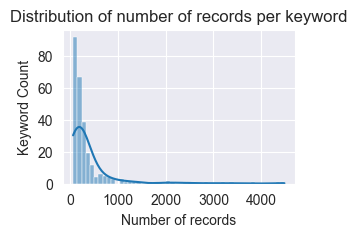

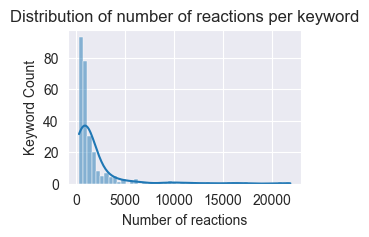

Min. records per keyword: 66 | Max. records per keyword: 4484 | Avg. records per keyword: 398.24632352941177
Min. reactions per keyword: 304 | Max. reactions per keyword: 21915 | Avg. reactions per keyword: 1865.3933823529412


In [6]:
# see the distribution of reactions/records per keyword
n_records = [len(s_kw_2_subm_ids[k]) for k in s_kws]
plt.figure(figsize=(3, 2))
sns.histplot(n_records, bins=50, kde=True)
plt.title("Distribution of number of records per keyword")
plt.xlabel("Number of records")
plt.ylabel("Keyword Count")
plt.show() 

n_reactions = [np.sum([len(s_subm_id_2_entry[subm_id]["reactions"]) for subm_id in s_kw_2_subm_ids[k]]) for k in s_kws]
plt.figure(figsize=(3, 2))
sns.histplot(n_reactions, bins=50, kde=True)
plt.title("Distribution of number of reactions per keyword")
plt.xlabel("Number of reactions")
plt.ylabel("Keyword Count")
plt.show()

print(f"Min. records per keyword: {min(n_records)} | Max. records per keyword: {max(n_records)} | Avg. records per keyword: {np.mean(n_records)}")
print(f"Min. reactions per keyword: {min(n_reactions)} | Max. reactions per keyword: {max(n_reactions)} | Avg. reactions per keyword: {np.mean(n_reactions)}")

In [7]:
# instead of orient around keywords, do it subreddit/community-wise

# so basically keep the same data structure, just filter out the entries that do not have any of the keywords
# already have: 
    # s_kw_2_subm_ids:   selected keyword to matching submission ids, dict of sets
    # s_subm_id_2_entry: matched submission id to entry, dict of dicts
    # subr_2_info:       subreddit to info, dict of dicts

# only need subreddit to subm_ids (maybe do it monthly?)
subr_2_monthly_subm_ids = defaultdict(lambda: defaultdict(set))  # subreddit to month to submission ids
for subreddit, data in tqdm(all_records.items(), desc="Over 207 subreddits"):
    for month, records in data['monthly_record'].items():
        for idx, record in enumerate(records):
            subm_id = record['submission_id']
            if subm_id in s_subm_id_2_entry:
                subr_2_monthly_subm_ids[subreddit][month].add(subm_id)

del all_records  # free up memory


Over 207 subreddits:   0%|          | 0/207 [00:00<?, ?it/s]

In [9]:
# change set to list for easier JSON serialization
for k in s_kw_2_subm_ids:
    s_kw_2_subm_ids[k] = list(s_kw_2_subm_ids[k])
for subreddit, monthly_subm_ids in subr_2_monthly_subm_ids.items():
    for month, subm_ids in monthly_subm_ids.items():
        subr_2_monthly_subm_ids[subreddit][month] = list(subm_ids)
        
# save data
output_dpath = './comm_reactions.json'
output_data = {
    "keyw_2_subm_ids": s_kw_2_subm_ids,
    "subr_2_monthly_subm_ids": subr_2_monthly_subm_ids,
    "subr_2_info": subr_2_info,
    "subm_id_2_entry": s_subm_id_2_entry,
}
with open(output_dpath, 'w') as f:
    json.dump(output_data, f, indent=4)
print(f"Data saved to {output_dpath}")

Data saved to ./comm_reactions.json
